In [2]:
import pandas as pd 
import geopandas as gpd
URL = ('https://raw.githubusercontent.com/carmengg/eds220-hwk-1/main/data/earthquake_data.csv')
earthquakes = pd.read_csv(URL)

countries = gpd.read_file('data/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp')
import matplotlib.pyplot as plt

Steps:\
1. Filter for magnitude at least 6.5 in 2014.
2. Map the countries.
3. Plot the filtered earthquakes.

In [8]:
earthquakes.head()

,time,latitude,longitude,depth,mag,id,place,type
0,2014-01-31 23:53:37.000,60.252000,-152.7081,90.20,1.10,ak11155107,"26km S of Redoubt Volcano, Alaska",earthquake
1,2014-01-31 23:48:35.452,37.070300,-115.1309,0.00,1.33,nn00436847,"32km S of Alamo, Nevada",earthquake
2,2014-01-31 23:47:24.000,64.671700,-149.2528,7.10,1.30,ak11151142,"12km NNW of North Nenana, Alaska",earthquake
3,2014-01-31 23:30:54.000,63.188700,-148.9575,96.50,0.80,ak11151135,"22km S of Cantwell, Alaska",earthquake
4,2014-01-31 23:30:52.210,32.616833,-115.6925,10.59,1.34,ci37171541,"10km WNW of Progreso, Mexico",earthquake


In [10]:
filter_eq = earthquakes[earthquakes['mag'] >= 6.5]

In [12]:
points = gpd.points_from_xy(filter_eq['longitude'], filter_eq['latitude'])
earthquakes_mags = gpd.GeoDataFrame(filter_eq, geometry=points, crs='EPSG:4326')

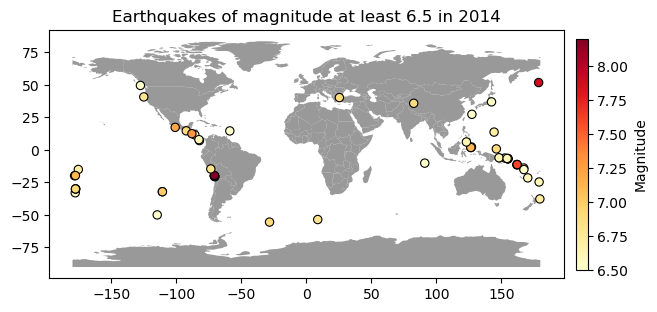

In [28]:
fig, ax = plt.subplots(figsize=(8,6))

countries.plot(ax = ax,
               color = 'grey',
               alpha = 0.8)

earthquakes_mags.plot(ax = ax,
               column = 'mag',
               cmap='YlOrRd',
               edgecolor='black',
               linewidth=0.8,
               legend=True,
               legend_kwds={'label': 'Magnitude', 'orientation': 'vertical', 'shrink': 0.5, 'pad': 0.02})

ax.set_title("Earthquakes of magnitude at least 6.5 in 2014")
plt.show()